# Maintained NUTS and rank-normalized diagnostics

Read the maintained implementation through its public API, then verify the rank/folded diagnostic independently. A library name does not establish a good posterior sample.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
ROOT=Path.cwd()
if ROOT.name == "notebooks": ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
torch.set_num_threads(1)
from sampling_lab.targets import load_target
from sampling_lab.artifacts import sha256
def read(path): return json.loads((ROOT/path).read_text())
def numeric(name): return np.load(ROOT/"assets/source_data"/(name+".npz"),allow_pickle=False)
%matplotlib inline


## Independent implementation check

In [2]:
import arviz as az
from sampling_lab.diagnostics import split_rank_rhat_oracle
source=numeric("gaussian_nuts_dispersed_0.1");x=source["observables"][:,:,0]
expected=split_rank_rhat_oracle(x);actual=float(az.rhat(x,method="rank"))
np.testing.assert_allclose(expected,actual,atol=1e-12)
print("Independent rank/folded Rhat",expected)
print(read("results/reference/sampling/gaussian_nuts_dispersed_0.1/metrics.json")["diagnostics"]["bulk_ess"])

Independent rank/folded Rhat 1.0007504023566776
[6375.877074020619, 6263.236993275812]


## Inspect measured evidence

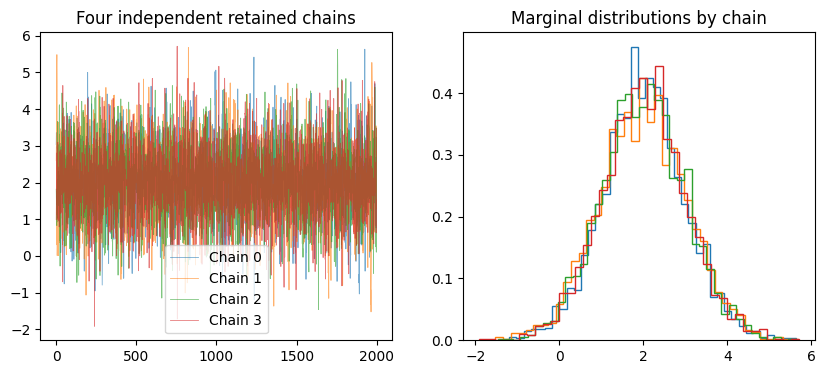

ESS can exceed draw count with negative autocorrelation; MCSE is conditional, not model uncertainty.


In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4))
for i in range(4):
 axes[0].plot(x[i],lw=.6,alpha=.6,label=f"Chain {i}")
 axes[1].hist(x[i],bins=40,density=True,histtype="step")
axes[0].set(title="Four independent retained chains");axes[0].legend();axes[1].set(title="Marginal distributions by chain");plt.show()
print("ESS can exceed draw count with negative autocorrelation; MCSE is conditional, not model uncertainty.")

## Interpretation and next step

Read the [theory](../docs/theory.md), [diagnostic scope](../docs/diagnostics.md), and [data protocol](../docs/data_and_protocols.md). Change one declared preset in a separate output directory; keep warmup, test evaluation and model selection distinct. The [interactive explorer](../docs/explorer.html) exposes the complete recorded comparisons.